<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Bubble Plots**


Estimated time needed: **30** minutes


In this lab, you will focus on visualizing data.

The dataset will be directly loaded into pandas for analysis and visualization.

You will use various visualization techniques to explore the data and uncover key trends.


## Objectives


In this lab, you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two data features.

-   Visualize composition of data.

-   Visualize comparison of data.


#### Setup: Working with the Database
**Install and import the needed libraries**


In [1]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
# !pip install matplotlib
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')

import pandas as pd
import matplotlib.pyplot as plt

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [2]:
# Step 1: Download the dataset
# (cached locally so the notebook still runs when the network is down)
import os
import urllib.request
import urllib.error

data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
local_file = 'survey-data.csv'

def load_dataset(url, local_path, retries=3):
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        try:
            return pd.read_csv(local_path)
        except Exception:
            pass
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            urllib.request.urlretrieve(url, local_path)
            return pd.read_csv(local_path)
        except (urllib.error.URLError, OSError) as e:
            last_err = e
            print(f"Download attempt {attempt}/{retries} failed: {e}")
    raise RuntimeError(
        "Could not download the dataset.\n"
        f"URL: {url}\nLast error: {last_err}\n"
        "Check your internet connection / VPN / proxy, or place a copy of the "
        f"CSV named '{local_path}' next to this notebook."
    )

df = load_dataset(data_url, local_file)

# Display the first few rows of the data to understand its structure
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Exploring Data Distributions Using Bubble Plots


#### 1. Bubble Plot for Age vs. Frequency of Participation


- Visualize the relationship between respondents’ age and their participation frequency (`SOPartFreq`) using a bubble plot.

- Use the size of the bubbles to represent their job satisfaction (`JobSat`).


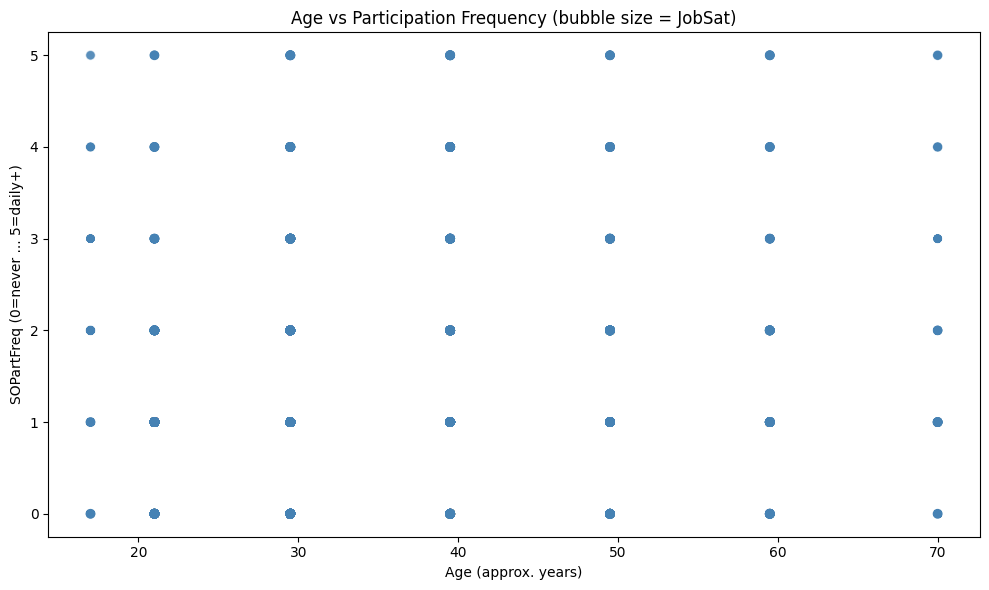

In [3]:
##Write your code here
# Bubble plot: Age (x) vs SOPartFreq (y), bubble size = JobSat
age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
part_map = {
    'I have never participated in Q&A on Stack Overflow': 0,
    'Less than once per month or monthly': 1,
    'A few times per month or weekly': 2,
    'A few times per week': 3,
    'Daily or almost daily': 4,
    'Multiple times per day': 5,
}
plot_df = df[['Age', 'SOPartFreq', 'JobSat']].dropna(subset=['Age', 'SOPartFreq']).copy()
plot_df['AgeNum'] = plot_df['Age'].map(age_mid)
plot_df['PartNum'] = plot_df['SOPartFreq'].map(part_map)
plot_df = plot_df.dropna(subset=['AgeNum', 'PartNum'])

plt.figure(figsize=(10, 6))
plt.scatter(plot_df['AgeNum'], plot_df['PartNum'],
            s=plot_df['JobSat'].fillna(plot_df['JobSat'].median()) * 5,
            alpha=0.3, c='steelblue', edgecolors='none')
plt.title('Age vs Participation Frequency (bubble size = JobSat)')
plt.xlabel('Age (approx. years)')
plt.ylabel('SOPartFreq (0=never ... 5=daily+)')
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Compensation vs. Job Satisfaction


-Visualize the relationship between yearly compensation (`ConvertedCompYearly`) and job satisfaction (`JobSat`).

- Use the size of the bubbles to represent respondents’ age.


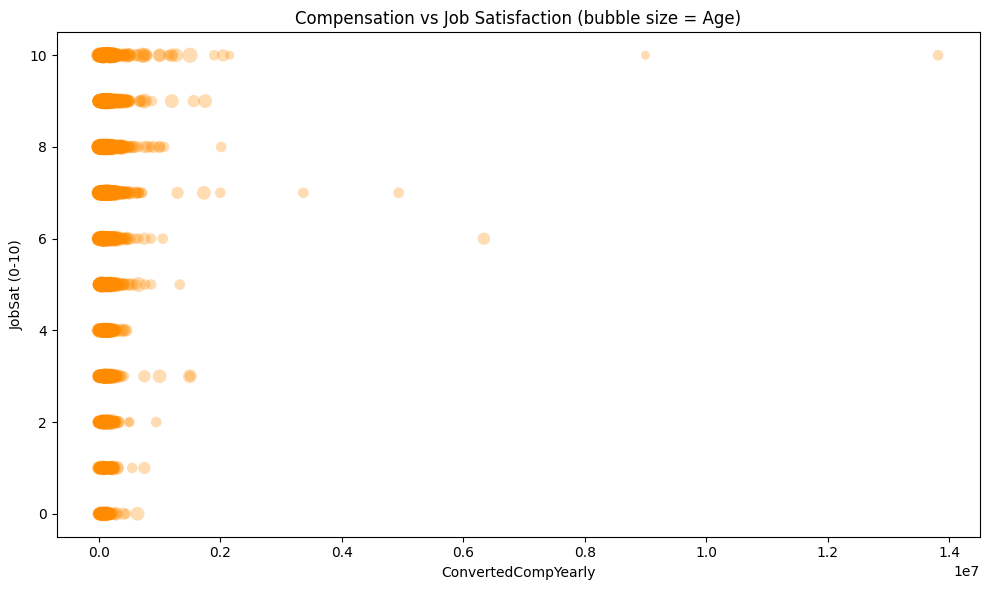

In [4]:
##Write your code here
# Bubble plot: ConvertedCompYearly (x) vs JobSat (y), bubble size = Age
age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
plot_df = df[['ConvertedCompYearly', 'JobSat', 'Age']].dropna(subset=['ConvertedCompYearly', 'JobSat']).copy()
plot_df['AgeNum'] = plot_df['Age'].map(age_mid)
plot_df = plot_df.dropna(subset=['AgeNum'])

plt.figure(figsize=(10, 6))
plt.scatter(plot_df['ConvertedCompYearly'], plot_df['JobSat'],
            s=plot_df['AgeNum'] * 2, alpha=0.3, c='darkorange', edgecolors='none')
plt.title('Compensation vs Job Satisfaction (bubble size = Age)')
plt.xlabel('ConvertedCompYearly')
plt.ylabel('JobSat (0-10)')
plt.tight_layout()
plt.show()

### Task 2: Analyzing Relationships Using Bubble Plots


#### 1. Bubble Plot of Technology Preferences by Age

- Visualize the popularity of programming languages respondents have worked with (`LanguageHaveWorkedWith`) across age groups.

- Use bubble size to represent the frequency of each language.



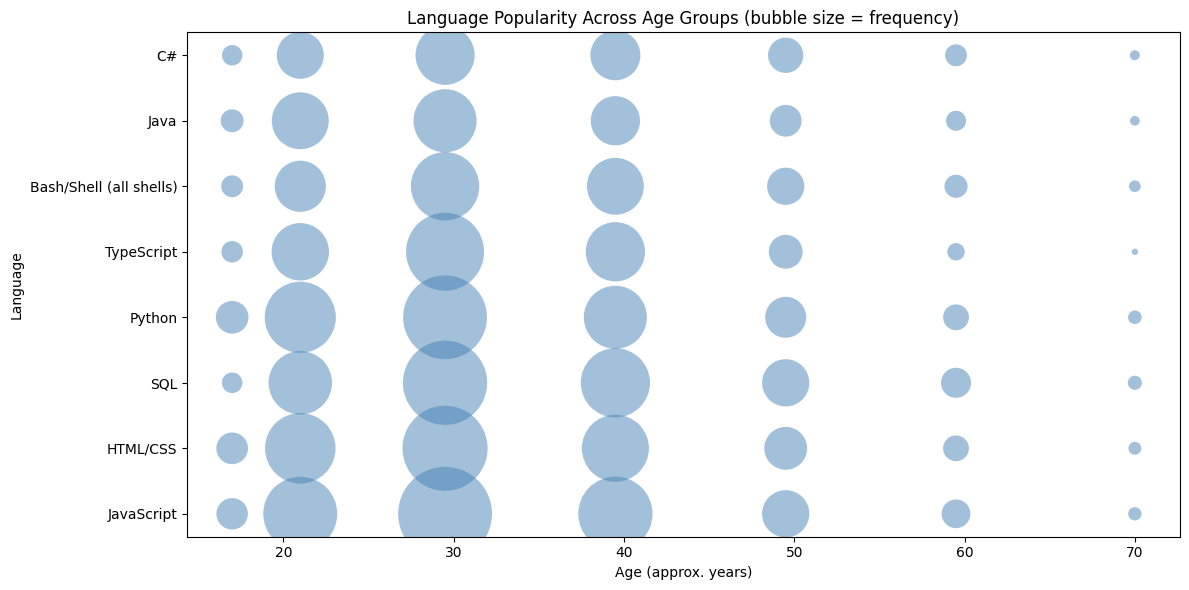

In [5]:
##Write your code here
# Bubble plot: LanguageHaveWorkedWith popularity across age groups
# x = Age (numeric), y = language (index), bubble size = frequency
age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
lang_df = df[['LanguageHaveWorkedWith', 'Age']].dropna(subset=['LanguageHaveWorkedWith', 'Age']).copy()
lang_df['Language'] = lang_df['LanguageHaveWorkedWith'].str.split(';')
exploded = lang_df.explode('Language')
exploded['AgeNum'] = exploded['Age'].map(age_mid)
exploded = exploded.dropna(subset=['AgeNum'])

# Aggregate frequency per (language, age)
agg = exploded.groupby(['Language', 'AgeNum']).size().reset_index(name='freq')
# Keep top 8 languages by total frequency
top_langs = exploded['Language'].value_counts().head(8).index.tolist()
agg = agg[agg['Language'].isin(top_langs)]

lang_to_y = {lang: i for i, lang in enumerate(top_langs)}
agg['LangY'] = agg['Language'].map(lang_to_y)

plt.figure(figsize=(12, 6))
plt.scatter(agg['AgeNum'], agg['LangY'], s=agg['freq'] / 3, alpha=0.5, c='steelblue', edgecolors='none')
plt.yticks(range(len(top_langs)), top_langs)
plt.title('Language Popularity Across Age Groups (bubble size = frequency)')
plt.xlabel('Age (approx. years)')
plt.ylabel('Language')
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Preferred Databases vs. Job Satisfaction

- Explore the relationship between preferred databases (`DatabaseWantToWorkWith`) and job satisfaction.

- Use bubble size to indicate the number of respondents for each database.


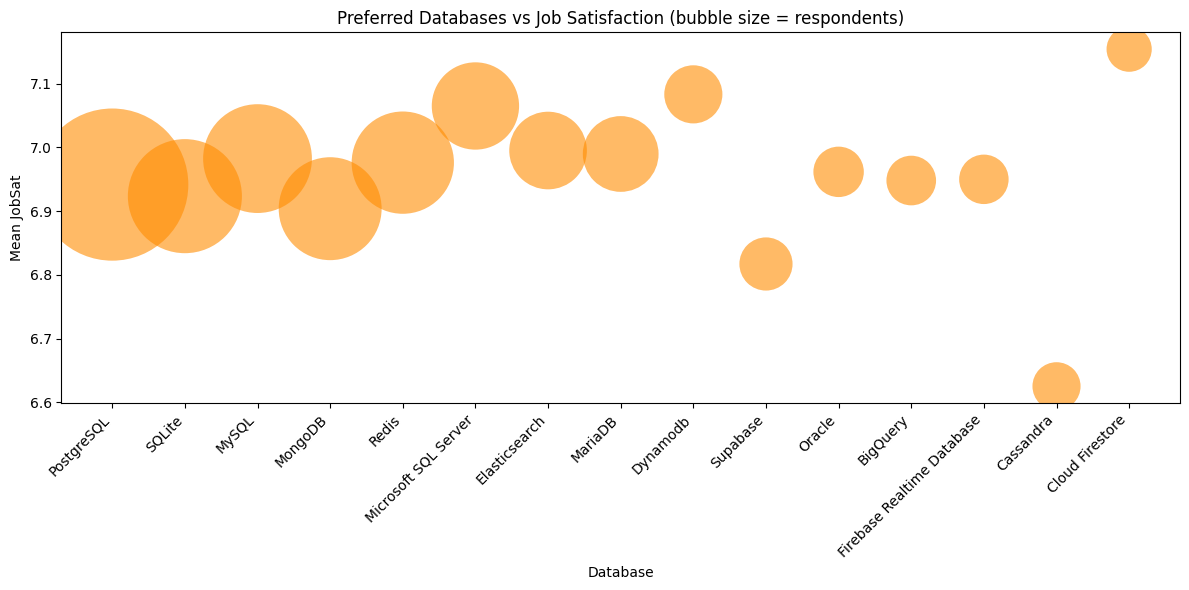

In [6]:
##Write your code here
# Bubble plot: DatabaseWantToWorkWith (x) vs JobSat (y), bubble size = count
db_df = df[['DatabaseWantToWorkWith', 'JobSat']].dropna(subset=['DatabaseWantToWorkWith']).copy()
db_df['Database'] = db_df['DatabaseWantToWorkWith'].str.split(';')
exploded = db_df.explode('Database')

agg = exploded.groupby('Database').agg(
    mean_jobsat=('JobSat', 'mean'),
    count=('JobSat', 'size'),
).reset_index()
agg = agg[agg['count'] >= 50].sort_values('count', ascending=False).head(15)

db_to_x = {db: i for i, db in enumerate(agg['Database'])}
agg['DbX'] = agg['Database'].map(db_to_x)

plt.figure(figsize=(12, 6))
plt.scatter(agg['DbX'], agg['mean_jobsat'], s=agg['count'] / 2, alpha=0.6, c='darkorange', edgecolors='none')
plt.xticks(range(len(agg)), agg['Database'], rotation=45, ha='right')
plt.title('Preferred Databases vs Job Satisfaction (bubble size = respondents)')
plt.xlabel('Database')
plt.ylabel('Mean JobSat')
plt.tight_layout()
plt.show()

### Task 3: Comparing Data Using Bubble Plots


#### 1. Bubble Plot for Compensation Across Developer Roles

- Visualize compensation (`ConvertedCompYearly`) across different developer roles (`DevType`).

- Use bubble size to represent job satisfaction.


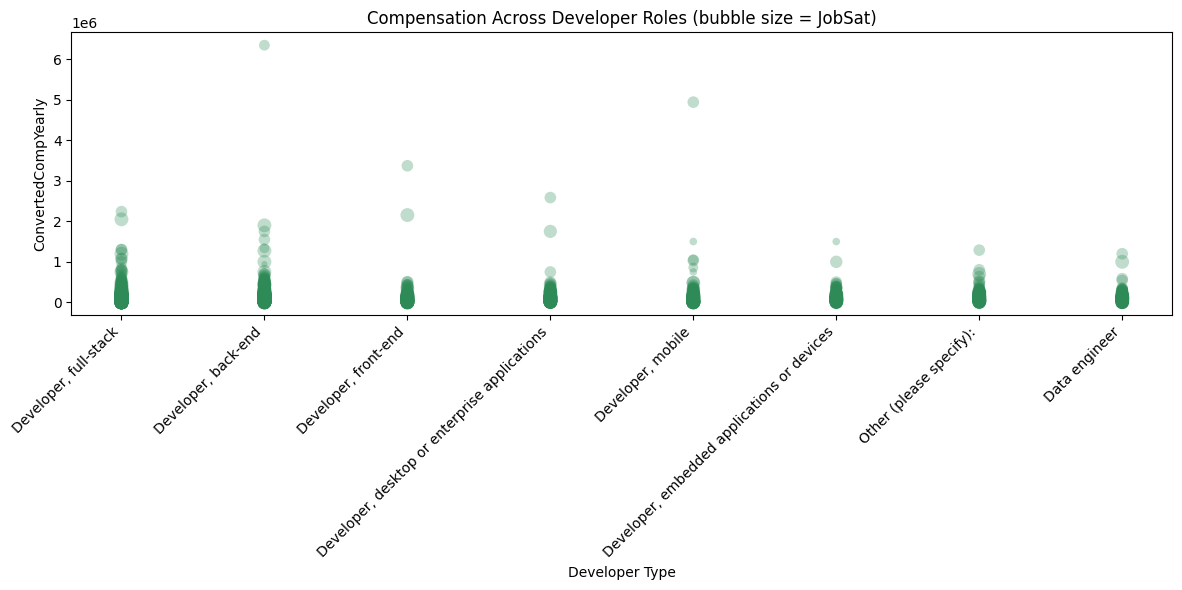

In [7]:
##Write your code here
# Bubble plot: DevType (x) vs ConvertedCompYearly (y), bubble size = JobSat
dev_df = df[['DevType', 'ConvertedCompYearly', 'JobSat']].dropna(subset=['DevType', 'ConvertedCompYearly']).copy()
dev_df['DevType'] = dev_df['DevType'].str.split(';').str[0]
top_devs = dev_df['DevType'].value_counts().head(8).index.tolist()
dev_df = dev_df[dev_df['DevType'].isin(top_devs)]

dev_to_x = {d: i for i, d in enumerate(top_devs)}
dev_df['DevX'] = dev_df['DevType'].map(dev_to_x)

plt.figure(figsize=(12, 6))
plt.scatter(dev_df['DevX'], dev_df['ConvertedCompYearly'],
            s=dev_df['JobSat'].fillna(dev_df['JobSat'].median()) * 10,
            alpha=0.3, c='seagreen', edgecolors='none')
plt.xticks(range(len(top_devs)), top_devs, rotation=45, ha='right')
plt.title('Compensation Across Developer Roles (bubble size = JobSat)')
plt.xlabel('Developer Type')
plt.ylabel('ConvertedCompYearly')
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Collaboration Tools by Age

- Visualize the relationship between the collaboration tools used (`NEWCollabToolsHaveWorkedWith`) and age groups.

- Use bubble size to represent the frequency of tool usage.


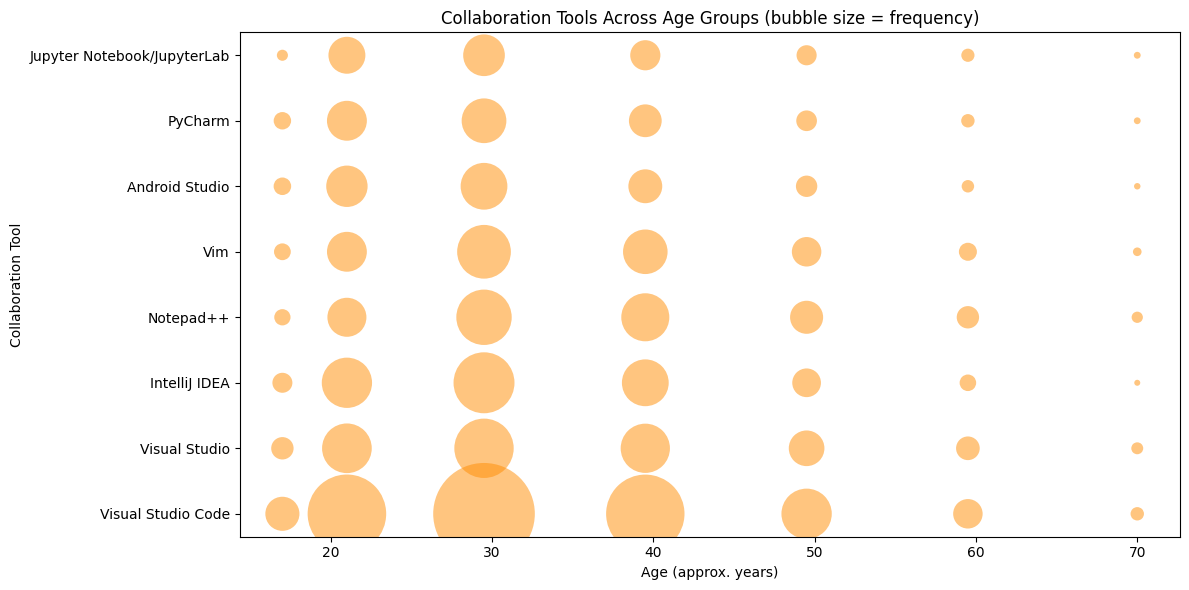

In [8]:
##Write your code here
# Bubble plot: NEWCollabToolsHaveWorkedWith vs Age, bubble size = frequency
age_mid = {
    'Under 18 years old': 17, '18-24 years old': 21, '25-34 years old': 29.5,
    '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
    '65 years or older': 70,
}
tool_df = df[['NEWCollabToolsHaveWorkedWith', 'Age']].dropna(subset=['NEWCollabToolsHaveWorkedWith', 'Age']).copy()
tool_df['Tool'] = tool_df['NEWCollabToolsHaveWorkedWith'].str.split(';')
exploded = tool_df.explode('Tool')
exploded['AgeNum'] = exploded['Age'].map(age_mid)
exploded = exploded.dropna(subset=['AgeNum'])

# Aggregate frequency per (tool, age)
agg = exploded.groupby(['Tool', 'AgeNum']).size().reset_index(name='freq')
top_tools = exploded['Tool'].value_counts().head(8).index.tolist()
agg = agg[agg['Tool'].isin(top_tools)]

tool_to_y = {t: i for i, t in enumerate(top_tools)}
agg['ToolY'] = agg['Tool'].map(tool_to_y)

plt.figure(figsize=(12, 6))
plt.scatter(agg['AgeNum'], agg['ToolY'], s=agg['freq'] / 3, alpha=0.5, c='darkorange', edgecolors='none')
plt.yticks(range(len(top_tools)), top_tools)
plt.title('Collaboration Tools Across Age Groups (bubble size = frequency)')
plt.xlabel('Age (approx. years)')
plt.ylabel('Collaboration Tool')
plt.tight_layout()
plt.show()

### Task 4: Visualizing Technology Trends Using Bubble Plots


#### 1. Bubble Plot for Preferred Web Frameworks vs. Job Satisfaction

- Explore the relationship between preferred web frameworks (`WebframeWantToWorkWith`) and job satisfaction.

- Use bubble size to represent the number of respondents.



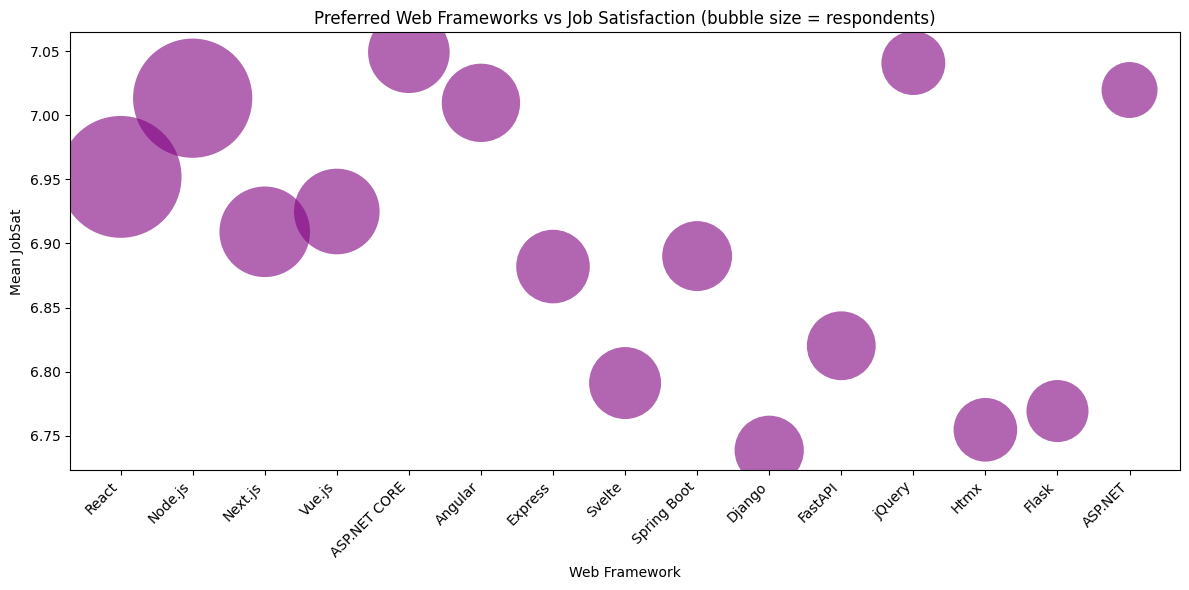

In [9]:
##Write your code here
# Bubble plot: WebframeWantToWorkWith (x) vs JobSat (y), bubble size = count
wf_df = df[['WebframeWantToWorkWith', 'JobSat']].dropna(subset=['WebframeWantToWorkWith']).copy()
wf_df['Webframe'] = wf_df['WebframeWantToWorkWith'].str.split(';')
exploded = wf_df.explode('Webframe')

agg = exploded.groupby('Webframe').agg(
    mean_jobsat=('JobSat', 'mean'),
    count=('JobSat', 'size'),
).reset_index()
agg = agg[agg['count'] >= 50].sort_values('count', ascending=False).head(15)

wf_to_x = {w: i for i, w in enumerate(agg['Webframe'])}
agg['WfX'] = agg['Webframe'].map(wf_to_x)

plt.figure(figsize=(12, 6))
plt.scatter(agg['WfX'], agg['mean_jobsat'], s=agg['count'] / 2, alpha=0.6, c='purple', edgecolors='none')
plt.xticks(range(len(agg)), agg['Webframe'], rotation=45, ha='right')
plt.title('Preferred Web Frameworks vs Job Satisfaction (bubble size = respondents)')
plt.xlabel('Web Framework')
plt.ylabel('Mean JobSat')
plt.tight_layout()
plt.show()

#### 2. Bubble Plot for Admired Technologies Across Countries

- Visualize the distribution of admired technologies (`LanguageAdmired`) across different countries (`Country`).

- Use bubble size to represent the frequency of admiration.



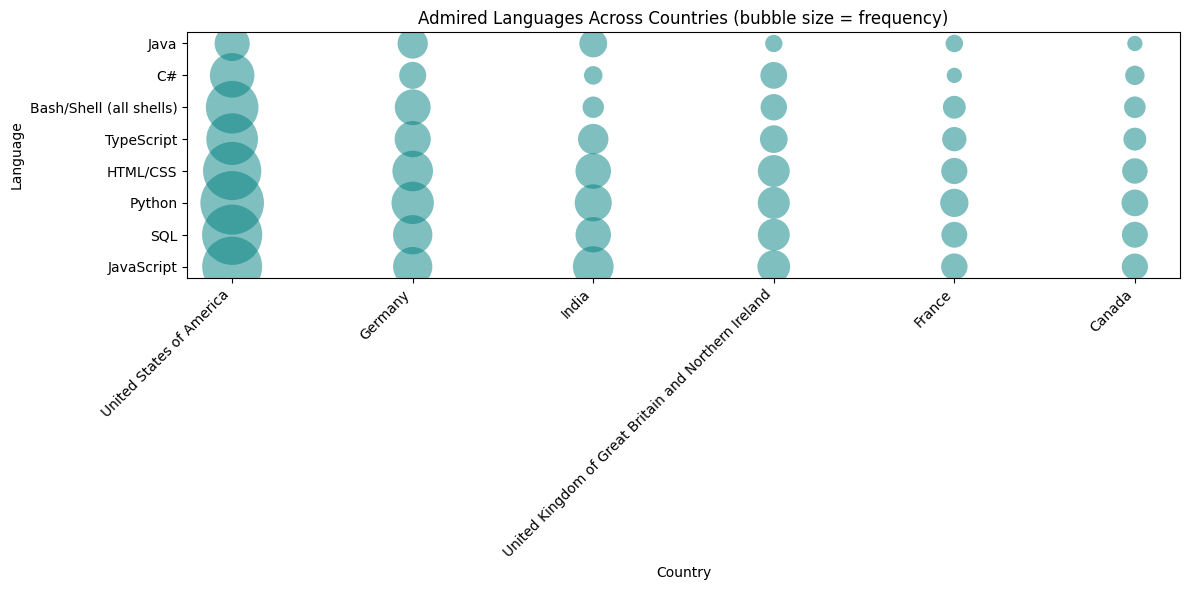

In [10]:
##Write your code here
# Bubble plot: LanguageAdmired across Country, bubble size = frequency
la_df = df[['LanguageAdmired', 'Country']].dropna(subset=['LanguageAdmired', 'Country']).copy()
la_df['Language'] = la_df['LanguageAdmired'].str.split(';')
exploded = la_df.explode('Language')

# Top 6 countries and top 8 languages
top_countries = exploded['Country'].value_counts().head(6).index.tolist()
top_langs = exploded['Language'].value_counts().head(8).index.tolist()
exploded = exploded[exploded['Country'].isin(top_countries) & exploded['Language'].isin(top_langs)]

agg = exploded.groupby(['Country', 'Language']).size().reset_index(name='freq')
country_to_x = {c: i for i, c in enumerate(top_countries)}
lang_to_y = {l: i for i, l in enumerate(top_langs)}
agg['CountryX'] = agg['Country'].map(country_to_x)
agg['LangY'] = agg['Language'].map(lang_to_y)

plt.figure(figsize=(12, 6))
plt.scatter(agg['CountryX'], agg['LangY'], s=agg['freq'] / 2, alpha=0.5, c='teal', edgecolors='none')
plt.xticks(range(len(top_countries)), top_countries, rotation=45, ha='right')
plt.yticks(range(len(top_langs)), top_langs)
plt.title('Admired Languages Across Countries (bubble size = frequency)')
plt.xlabel('Country')
plt.ylabel('Language')
plt.tight_layout()
plt.show()

## Final Step: Review


After completing the lab, you will have extensively used bubble plots to gain insights into developer community preferences, demographics, compensation trends, and job satisfaction.


## Summary


After completing this lab, you will be able to:

- Create and interpret bubble plots to analyze relationships and compositions within datasets.

- Use bubble plots to explore developer preferences, compensation trends, and satisfaction levels.

- Apply bubble plots to visualize complex relationships involving multiple dimensions effectively.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-29|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
